# 08.9 · Data augmentation and transfer learning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/08-deep-learning/09-augmentation-transfer-learning/lesson.ipynb)

Read the [README](README.md) first. This notebook trains four models on the same **1,000 photos** and compares them on 500 photos none of them has seen.

The first run downloads 229 MB of flower photos and about 10 MB of pretrained weights; after that everything is cached. Each model trains in seconds to a minute on a GPU and in a few minutes on a laptop CPU. Accuracies vary by a point or two between machines.

In [1]:
import os, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"        # hide TensorFlow's C++ start-up messages
warnings.filterwarnings("ignore")                # hide library deprecation notices
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers
keras.utils.set_random_seed(42)                  # same start every run (results still vary slightly by machine)
print("Keras", keras.__version__, "· backend", keras.backend.backend())

import pathlib

def flower_folder():
    """Download the 5-class flower photos once (229 MB) and return the folder."""
    path = keras.utils.get_file(
        "flower_photos", untar=True,
        origin="https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz")
    return next(p.parent for p in pathlib.Path(path).rglob("daisy") if p.is_dir())

def load_flowers(n_train=200, n_val=40, n_test=100, size=160, seed=0):
    """Pick n images per class for train/val/test; return uint8 arrays (small in memory)."""
    root = flower_folder()
    classes = sorted(p.name for p in root.iterdir() if p.is_dir())
    rng = np.random.default_rng(seed)
    parts = {"train": (0, n_train), "val": (n_train, n_train + n_val),
             "test": (n_train + n_val, n_train + n_val + n_test)}
    data = {k: ([], []) for k in parts}
    for label, name in enumerate(classes):
        files = sorted((root / name).glob("*.jpg"))
        rng.shuffle(files)
        for k, (a, b) in parts.items():
            for f in files[a:b]:
                img = keras.utils.load_img(f, target_size=(size, size))
                data[k][0].append(np.asarray(img, dtype="uint8"))
                data[k][1].append(label)
    out = {k: (np.stack(v[0]), np.array(v[1])) for k, v in data.items()}
    return out, classes

data, CLASSES = load_flowers(n_train=200, n_val=40, n_test=100)
(x_train, y_train), (x_val, y_val), (x_test, y_test) = data["train"], data["val"], data["test"]
print("classes:", CLASSES)
print("train", x_train.shape, " val", x_val.shape, " test", x_test.shape,
      f" ({x_train.nbytes / 1e6:.0f} MB as uint8)")

Keras 3.15.1 · backend tensorflow


classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
train (1000, 160, 160, 3)  val (200, 160, 160, 3)  test (500, 160, 160, 3)  (77 MB as uint8)


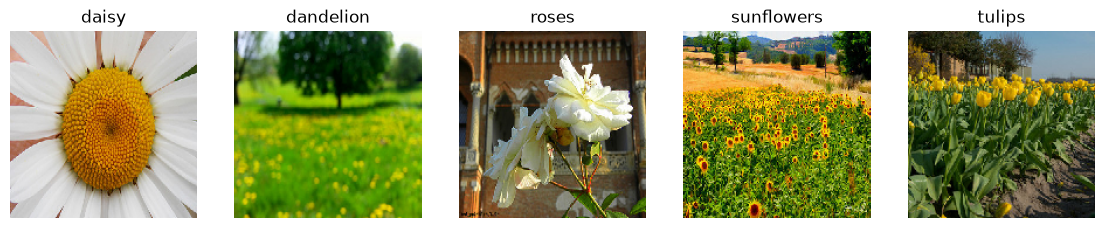

In [2]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for label, ax in enumerate(axes):
    ax.imshow(x_train[np.argmax(y_train == label)]); ax.set_title(CLASSES[label]); ax.axis("off")
plt.show()

## 1. Augmentation, by hand and in Keras

A horizontal flip reverses the order of the columns. On a 3×3 array:

In [3]:
tiny = np.array([[1, 2, 3],
                 [4, 5, 6],
                 [7, 8, 9]])
print(np.fliplr(tiny))

[[3 2 1]
 [6 5 4]
 [9 8 7]]


Keras' augmentation layers do this (plus rotations and zooms) at random, a fresh version every time a photo is used in training. Eight random versions of one photo:

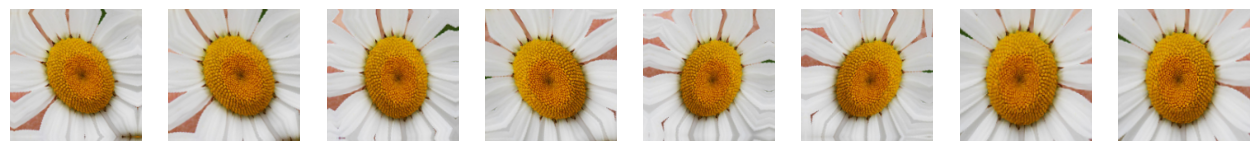

In [4]:
import time

augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),          # up to ±10% of a full turn (±36°)
    layers.RandomZoom(0.1),
], name="augment")

def fit_eval(model, epochs, lr=1e-3):
    """Train on the 1,000 photos, return (test accuracy, seconds)."""
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    start = time.time()
    model.fit(x_train, y_train, validation_data=(x_val, y_val),
              epochs=epochs, batch_size=32, verbose=0)
    return model.evaluate(x_test, y_test, verbose=0)[1], time.time() - start

def small_cnn(with_augmentation):
    steps = [keras.Input((160, 160, 3)), layers.Rescaling(1 / 255)]
    steps += [augment] if with_augmentation else []
    steps += [layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
              layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
              layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
              layers.GlobalAveragePooling2D(), layers.Dense(5, activation="softmax")]
    return keras.Sequential(steps)

def transfer_model(base_fn, n_classes=5):
    """Pretrained base (frozen) + augmentation + a new 5-class head."""
    base = base_fn(input_shape=(160, 160, 3), include_top=False, weights="imagenet", pooling="avg")
    base.trainable = False
    inputs = keras.Input((160, 160, 3))
    x = base(augment(inputs), training=False)
    outputs = layers.Dense(n_classes, activation="softmax")(layers.Dropout(0.2)(x))
    return keras.Model(inputs, outputs), base

def trainable(model):
    return sum(int(np.prod(w.shape)) for w in model.trainable_weights)

photo = x_train[:1].astype("float32")
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax in axes:
    ax.imshow(augment(photo, training=True)[0].numpy().astype("uint8")); ax.axis("off")
plt.show()

## 2. From scratch: a small CNN, with and without augmentation

The same kind of network as 08.8, sized for 160×160 colour photos.

In [5]:
results = {}
for aug in [False, True]:
    keras.utils.set_random_seed(42)
    model = small_cnn(aug)
    acc, secs = fit_eval(model, epochs=10)
    train_acc = model.evaluate(x_train, y_train, verbose=0)[1]
    name = "from scratch" + (" + augmentation" if aug else "")
    results[name] = (acc, trainable(model), secs)
    print(f"{name:<32} train {train_acc:.3f}  test {acc:.3f}  ({secs:.0f} s)")

from scratch                     train 0.568  test 0.552  (31 s)


from scratch + augmentation      train 0.525  test 0.514  (16 s)


Both are poor: about half right, where guessing among five classes gives 20%. A thousand photos are not enough to learn "what a petal looks like" from random filters.

And augmentation did not help. Look at the training accuracy: it is no higher than the test accuracy, so this small network is **underfitting**, not memorising (04.9). Augmentation is a cure for overfitting; giving an underfitting model a harder version of the task only makes things worse. The fix here is not more tricks, it is a better starting point.

## 3. Transfer learning: borrow a trained eye

MobileNetV3Small was trained on 1.3 million ImageNet photos. We keep everything except its final classification layer, freeze it, and train only a new 5-way output layer.

In [6]:
keras.utils.set_random_seed(42)
tl_model, base = transfer_model(keras.applications.MobileNetV3Small)
print(f"pretrained base: {base.count_params():,} weights (frozen)")
print(f"features per photo: {base.output.shape[-1]}")
print(f"trainable weights: {trainable(tl_model):,}")

pretrained base: 939,120 weights (frozen)
features per photo: 576
trainable weights: 2,885


In [7]:
acc, secs = fit_eval(tl_model, epochs=10)
results["transfer (frozen base)"] = (acc, trainable(tl_model), secs)
print(f"transfer, frozen base: test accuracy {acc:.3f}  ({secs:.0f} s)")

transfer, frozen base: test accuracy 0.846  (10 s)


## 4. Fine-tuning

Now unfreeze the top 20 layers of the base and keep training with a **much smaller learning rate**, so the pretrained filters adjust gently instead of being wrecked.

In [8]:
base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False
print(f"trainable weights now: {trainable(tl_model):,}")
acc, secs = fit_eval(tl_model, epochs=5, lr=1e-5)
results["transfer + fine-tune"] = (acc, trainable(tl_model), secs)
print(f"after fine-tuning: test accuracy {acc:.3f}  ({secs:.0f} s)")

trainable weights now: 353,429


after fine-tuning: test accuracy 0.848  (7 s)


In [9]:
import pandas as pd
pd.DataFrame(results, index=["test accuracy", "trainable weights", "seconds"]).T.round(3)

,test accuracy,trainable weights,seconds
from scratch,0.552,23909.0,30.580
from scratch + augmentation,0.514,23909.0,16.329
transfer (frozen base),0.846,2885.0,9.531
transfer + fine-tune,0.848,353429.0,7.013


## 5. The same idea with tools you already know

A frozen base turns each photo into a list of numbers (its **features**, or **embedding**). Once you have those, any classifier works, including logistic regression from Module 03. This is often the fastest way to try transfer learning.

In [10]:
from sklearn.linear_model import LogisticRegression
extractor = keras.applications.MobileNetV3Small(input_shape=(160, 160, 3), include_top=False,
                                                 weights="imagenet", pooling="avg")
f_train = extractor.predict(x_train, verbose=0)
f_test = extractor.predict(x_test, verbose=0)
print("feature table:", f_train.shape)
clf = LogisticRegression(max_iter=2000).fit(f_train, y_train)
print(f"logistic regression on MobileNet features: test accuracy {clf.score(f_test, y_test):.3f}")

feature table: (1000, 576)
logistic regression on MobileNet features: test accuracy 0.870


## 6. Where the transfer model still slips

In [11]:
from sklearn.metrics import confusion_matrix
pred = tl_model.predict(x_test, verbose=0).argmax(1)
print(pd.DataFrame(confusion_matrix(y_test, pred), index=CLASSES, columns=CLASSES))

            daisy  dandelion  roses  sunflowers  tulips
daisy          85          4      2           5       4
dandelion       1         86      1           7       5
roses           4          1     83           1      11
sunflowers      2          0      6          89       3
tulips          1          2     13           3      81


## Quiz answers

1. Making new, slightly changed copies of training photos (flips, small rotations, zooms) so the model sees more variety without new labels.
2. Only during training. At prediction time the layers pass photos through unchanged.
3. Reusing a network trained on a large dataset as the starting point for a different, smaller task.
4. 576 × 5 + 5 = 2,885.
5. A large learning rate would make big changes to the pretrained filters and destroy what they learned; small steps adjust them gently.

**Next:** [08.10 Sequences: RNNs and LSTMs](../10-sequences-rnn-lstm/)